# Smoke3D

Smoke3D files (`&SMOKE3D`) are written for rendering smoke and fire in Smokeview.

> **The files hold display codes, not physical values.** Every value is a single byte between
> 0 and 254: HRRPUV is scaled to `HRRPUV_MAX_SMV` (1200 kW/m³ by default) and cut off above
> it, temperature to `TEMP_MIN_SMV`..`TEMP_MAX_SMV`, soot is stored as obscuration
> (FDS < 6.11) or normalised per frame (FDS ≥ 6.11); see
> [#115](https://github.com/FireDynamics/fdsreader/issues/115). `to_physical()` converts the
> codes back, within the 8-bit resolution. For quantitative analysis slices, Plot3D or the
> CSV files are still the better source.

Run FDS on `fds_steckler/input_steckler.fds` first: the Steckler room with the default
Smoke3D output.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import fdsreader as fds

sim = fds.Simulation("./fds_steckler")
print([smoke.quantity for smoke in sim.smoke_3d])

[Quantity('SOOT DENSITY'), Quantity('HRRPUV'), Quantity('EFFECTIVE FLAME TEMPERATURE')]


The quantity names depend on the FDS version: FDS 6.11 writes the temperature as
`EFFECTIVE FLAME TEMPERATURE`. `SOOT DENSITY` is zero in this case, which sets no soot
yield, so the heat release rate per unit volume is shown.

In [2]:
hrrpuv = sim.smoke_3d.get_by_quantity("HRRPUV")
print("encoded as:", hrrpuv.kind, " format version:", hrrpuv.version)

q, saturated, coords = hrrpuv.to_physical(masked=True, fill=np.nan, return_saturated=True, return_coordinates=True)
print(q.shape, f"from {np.nanmin(q):.0f} to {np.nanmax(q):.0f} {hrrpuv.quantity.unit}")
print(f"cut off at the upper limit: {saturated.sum()} values")

encoded as: hrrpuv  format version: 1
(101, 37, 29, 23) from 0 to 1200 kW/m3
cut off at the upper limit: 1088 values


`to_physical` reads the limits FDS used from the `.smv` file and marks values that were cut
off at the upper limit. Summed up over the volume, the result stays below the heat release
rate from `CHID_hrr.csv`: the flame core lies above the limit, and small values round to zero.
That is why the CSV files remain the source for the total.

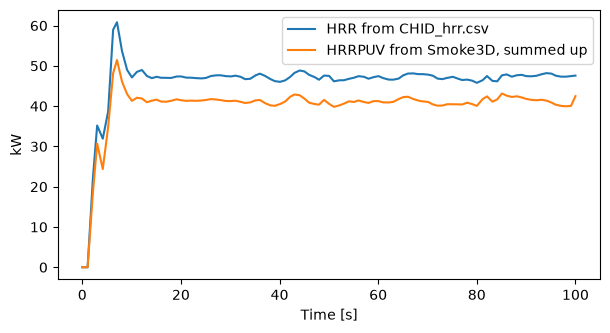

In [3]:
dx, dy, dz = (np.diff(coords[axis]).mean() for axis in ("x", "y", "z"))
from_smoke3d = np.nansum(q, axis=(1, 2, 3)) * dx * dy * dz

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(sim.hrr["Time"], sim.hrr["HRR"], label="HRR from CHID_hrr.csv")
ax.plot(hrrpuv.times, from_smoke3d, label="HRRPUV from Smoke3D, summed up")
ax.set(xlabel="Time [s]", ylabel="kW")
ax.legend();

## Render one frame

Zero is drawn transparent and the upper limit opaque, similar to Smokeview. The grey band is
the masked wall with the door.

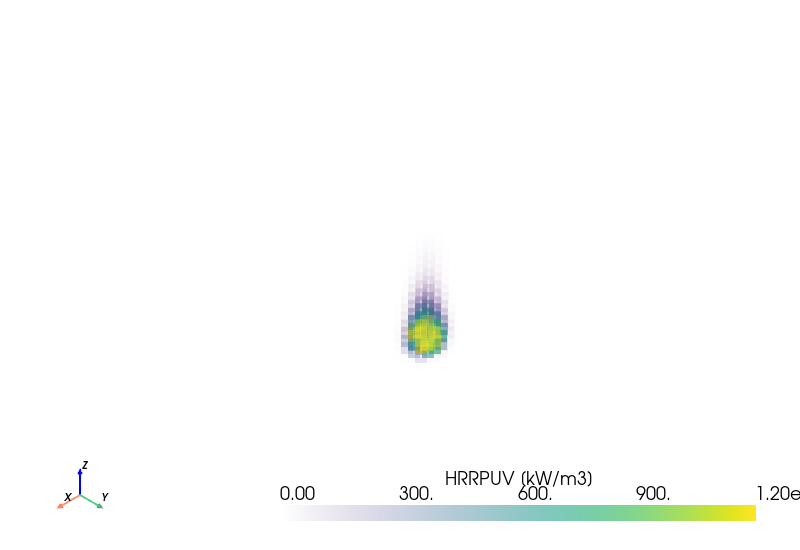

In [4]:
import pyvista as pv

# Render 3D views as static images, so they are stored in the notebook. Use "trame" or
# remove this line to rotate the views interactively.
pv.set_jupyter_backend("static")
pv.global_theme.window_size = [800, 550]

t = int(np.argmin(np.abs(np.array(hrrpuv.times) - 60.0)))
x, y, z = np.meshgrid(coords["x"], coords["y"], coords["z"], indexing="ij")
frame = pv.PolyData(np.column_stack((x.ravel(), y.ravel(), z.ravel())))
frame["HRRPUV"] = q[t].ravel()
frame.plot(
    opacity="linear",
    clim=(0, np.nanmax(q)),
    point_size=12,
    scalar_bar_args={"title": f"HRRPUV [{hrrpuv.quantity.unit}]"},
)

More in the [API reference](https://fdsreader.readthedocs.io/en/latest/api/smoke3d.html).